In [1]:
!pip -q install kagglehub

import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download(
    "kyanyoga/sample-sales-data"
)

# Find CSV file
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:")
for f in csv_files:
    print(f)

csv_path = csv_files[0]
print("\nUsing:", csv_path)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


100%|██████████| 77.5k/77.5k [00:00<00:00, 196kB/s]

Extracting files...
CSV files found:
C:\Users\Payal\.cache\kagglehub\datasets\kyanyoga\sample-sales-data\versions\1\sales_data_sample.csv

Using: C:\Users\Payal\.cache\kagglehub\datasets\kyanyoga\sample-sales-data\versions\1\sales_data_sample.csv


In [2]:
df = pd.read_csv(
    csv_path,
    encoding="latin-1"
)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Shape: (2823, 25)

Columns:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2 

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES"
]

X = df[features].apply(
    pd.to_numeric,
    errors="coerce"
)

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values with median
X = SimpleImputer(
    strategy="median"
).fit_transform(X)

# Standardize
X = StandardScaler().fit_transform(X)

print("Features prepared:", X.shape)

Features prepared: (2823, 3)


c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

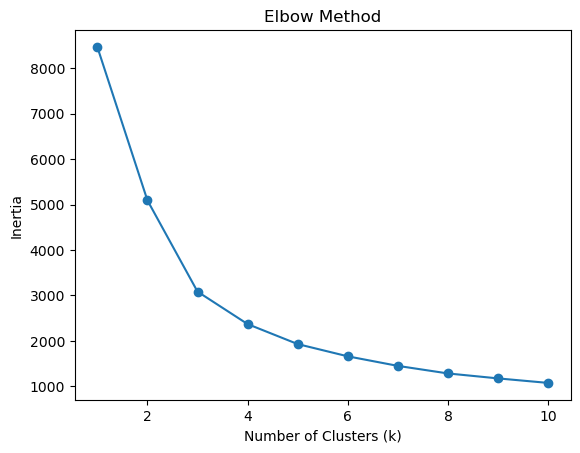

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(
    range(1, 11),
    inertia,
    "o-"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

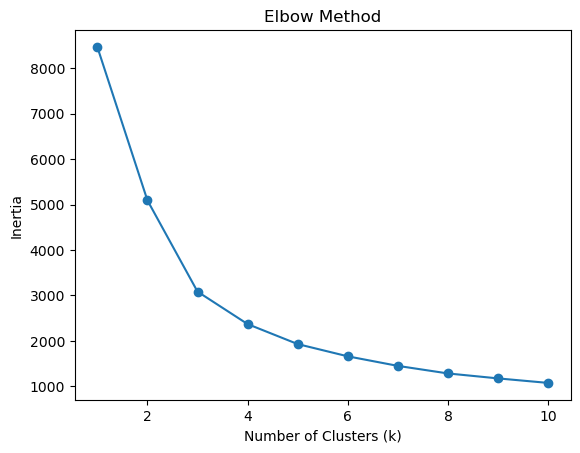

In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(
    range(1, 11),
    inertia,
    "o-"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [6]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=42
)

km_labels = kmeans.fit_predict(X)

print("K-Means cluster sizes:")
print(
    pd.Series(km_labels)
    .value_counts()
    .sort_index()
)

K-Means cluster sizes:
0     881
1     907
2    1035
Name: count, dtype: int64


In [7]:
from sklearn.cluster import AgglomerativeClustering

hierarchy = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

hc_labels = hierarchy.fit_predict(X)

print("Hierarchical cluster sizes:")
print(
    pd.Series(hc_labels)
    .value_counts()
    .sort_index()
)

Hierarchical cluster sizes:
0    1014
1     685
2    1124
Name: count, dtype: int64


In [8]:
result = df[
    ["QUANTITYORDERED", "PRICEEACH", "SALES"]
].copy()

result["KMeans_cluster"] = km_labels
result["Hierarchical_cluster"] = hc_labels

print(result.head())

   QUANTITYORDERED  PRICEEACH    SALES  KMeans_cluster  Hierarchical_cluster
0               30      95.70  2871.00               2                     2
1               34      81.35  2765.90               2                     2
2               41      94.74  3884.34               1                     1
3               45      83.26  3746.70               1                     0
4               49     100.00  5205.27               1                     1


In [9]:
print("K-Means Summary:")
print(
    result.groupby("KMeans_cluster")[features]
    .agg(["count", "mean"])
    .round(2)
)

print("\nHierarchical Summary:")
print(
    result.groupby("Hierarchical_cluster")[features]
    .agg(["count", "mean"])
    .round(2)
)

K-Means Summary:
               QUANTITYORDERED        PRICEEACH        SALES         
                         count   mean     count   mean count     mean
KMeans_cluster                                                       
0                          881  35.13       881  57.13   881  2009.83
1                          907  43.85       907  96.64   907  5584.01
2                         1035  27.39      1035  94.87  1035  3089.15

Hierarchical Summary:
                     QUANTITYORDERED        PRICEEACH        SALES         
                               count   mean     count   mean count     mean
Hierarchical_cluster                                                       
0                               1014  36.58      1014  60.35  1014  2238.07
1                                685  44.08       685  99.45   685  6081.75
2                               1124  28.27      1124  95.06  1124  3200.38


In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

coords = pca.fit_transform(X)

print(
    "Variance represented:",
    round(
        pca.explained_variance_ratio_.sum(),
        3
    )
)

Variance represented: 0.952


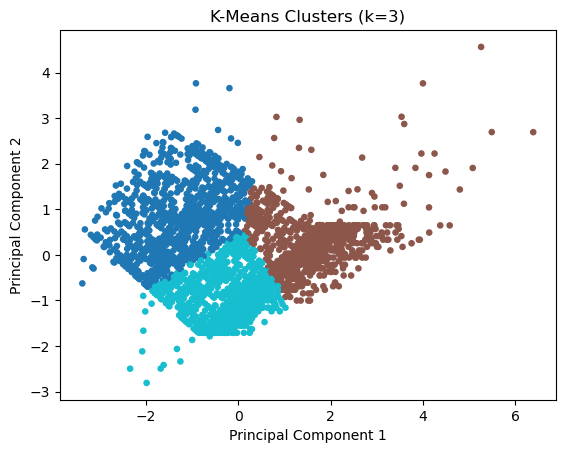

In [11]:
plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=km_labels,
    cmap="tab10",
    s=14
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(
    f"K-Means Clusters (k={k})"
)

plt.show()

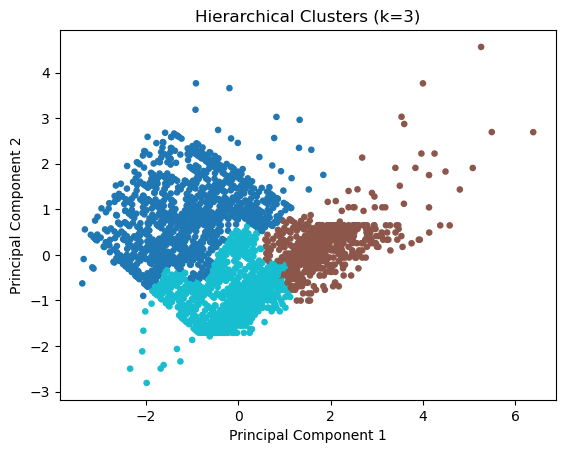

In [12]:
plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=hc_labels,
    cmap="tab10",
    s=14
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(
    f"Hierarchical Clusters (k={k})"
)

plt.show()

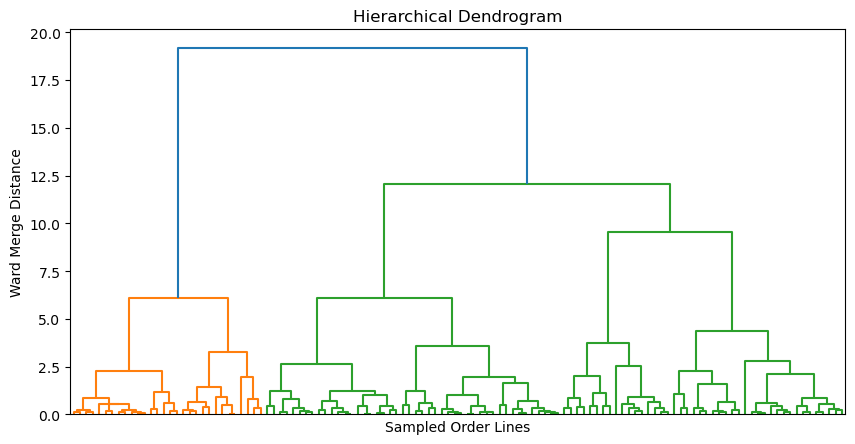

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Use maximum 120 samples for readable dendrogram
rng = np.random.default_rng(42)

sample_index = rng.choice(
    len(X),
    size=min(120, len(X)),
    replace=False
)

tree = linkage(
    X[sample_index],
    method="ward"
)

plt.figure(figsize=(10, 5))

dendrogram(
    tree,
    no_labels=True
)

plt.xlabel("Sampled Order Lines")
plt.ylabel("Ward Merge Distance")
plt.title("Hierarchical Dendrogram")

plt.show()